# Анализ подготовленных данных

Для каждого набора смотрим примеры, пропуски и количество связей buy/view. Плотность покупок — доля уникальных buy-пар среди всех возможных пар разных товаров каталога. При подсчёте A–B и B–A считаем одной связью. Запускайте ячейки каждого раздела по порядку.

In [10]:
%pip install -q pandas matplotlib


[notice] A new release of pip is available: 26.0.1 -> 26.3
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [ ]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt


ROOT = Path.cwd()
DATA = ROOT / "data" / "processed"
summary_rows = {}
plt.rcParams.update({"figure.figsize": (12, 4), "axes.grid": True, "grid.alpha": 0.2})

## Общие функции

In [12]:
def read_table(path):
    """Читает обработанный CSV, сохраняя ID строками."""
    columns = pd.read_csv(path, nrows=0).columns
    string_columns = [c for c in columns if c.endswith("_id") or "category" in c or c == "transactionid"]
    frame = pd.read_csv(path, dtype={c: "string" for c in string_columns})
    return frame


def quality(frame):
    """Показывает пропуски и полные дубликаты таблицы."""
    missing = frame.isna().sum()
    for column in frame.select_dtypes(include=["object", "string"]):
        missing[column] += frame[column].str.fullmatch(r"\s*", na=False).sum()
    display(pd.DataFrame({"пропуски": missing, "пропуски, %": missing / max(len(frame), 1) * 100}))
    print("Полных дубликатов:", frame.duplicated().sum())


def unique_edges(pairs, relation):
    """Возвращает уникальные неупорядоченные пары выбранного типа без самосвязей."""
    edges = pairs.loc[pairs.relation.eq(relation), ["source_id", "target_id"]].dropna().drop_duplicates()
    edges = edges[edges.source_id.ne(edges.target_id)].copy()
    reverse = edges.source_id.gt(edges.target_id)
    edges.loc[reverse, ["source_id", "target_id"]] = edges.loc[reverse, ["target_id", "source_id"]].to_numpy()
    return edges.drop_duplicates()

In [13]:
def graph_stats(pairs, catalog):
    """Считает наблюдения, уникальные связи и число buy-соседей каждого товара."""
    counts = {}
    for relation in ["buy", "view"]:
        edges = unique_edges(pairs, relation)
        counts[relation] = [pairs.relation.eq(relation).sum(), len(edges)]
        if relation == "buy":
            degree = pd.concat([edges.source_id, edges.target_id]).value_counts()
            degree = degree.reindex(catalog.dropna().unique(), fill_value=0)
    return pd.DataFrame(counts, index=["наблюдения", "уникальные связи"]).T, degree

## 1. Amazon Musical Instruments

In [14]:
name = "amazon"
frame = read_table(DATA / name / "items.csv.gz")
pairs = read_table(DATA / name / "pairs.csv.gz")

### Примеры строк · items

In [15]:
print(f"{name}/items: {len(frame):,} строк × {len(frame.columns)} столбцов")
display(frame.sample(min(5, len(frame)), random_state=42))

amazon/items: 112,135 строк × 5 столбцов


,item_id,title,description,category_path,category
48827,B0064ROGH6,Yamaha CM10V 10&quot; 2-Way Club Monitor Pair,['Like other members of the Club Concert serie...,Musical Instruments > Live Sound & Stage > Mon...,"Monitor, Speaker & Subwoofer Parts"
88243,B00QPH1NW6,HellsBelts 'Scorpion II&quot; Bullet Guitar Strap,['The &apos;Scorpion II&apos; - Bullet Guitar ...,Musical Instruments > Instrument Accessories >...,Straps
39594,B004LCBKFW,Bible Navigator Deluxe Edition: Holman CSB Edi...,"[""Bible Navigator Deluxe Edition combines the ...",Musical Instruments > Studio Recording Equipme...,Software
81521,B00L4EVWFS,DiMarzio Ionizer 7-String Neck Humbucker Picku...,"[""Ionizer 7-String Neck Humbucker Pickup Black...",Musical Instruments > Instrument Accessories >...,Pickups & Pickup Covers
101943,B0172GDJZC,Harmony Audio HA-C8A Pro DJ 8&quot; Powered 30...,"['', '<b>This Package Includes the Following I...",Musical Instruments > Live Sound & Stage > Mon...,Powered Cabinets


### Пропуски и дубликаты · items

In [16]:
quality(frame)

,пропуски,"пропуски, %"
item_id,0,0.000000
title,0,0.000000
description,0,0.000000
category_path,5646,5.035002
category,5646,5.035002


Полных дубликатов: 0


### Примеры строк · pairs

In [17]:
print(f"{name}/pairs: {len(pairs):,} строк × {len(pairs.columns)} столбцов")
display(pairs.sample(min(5, len(pairs)), random_state=42))

amazon/pairs: 330,361 строк × 5 столбцов


,source_id,target_id,relation,source_category,target_category
98442,B0002E594G,B0002E1IW8,view,Alto Sax,Alto Sax
272079,B00MFTFTX2,B01C4KTAKE,view,Steel-string Acoustics,Acoustic Guitars
109862,B0002IHGZ2,B0006ZXFZQ,view,Distortion & Overdrive,Distortion & Overdrive
266632,B00KGKBEKO,B0002CZW0Y,view,Windscreens & Pop Filters,Windscreens & Pop Filters
299400,B010JV4A14,B0105VDEVA,view,Singing Bowls,Singing Bowls


### Пропуски и дубликаты · pairs

In [18]:
quality(pairs)

,пропуски,"пропуски, %"
source_id,0,0.0
target_id,0,0.0
relation,0,0.0
source_category,0,0.0
target_category,0,0.0


Полных дубликатов: 0


### Примеры пар с названиями товаров

In [19]:
display(pairs.head().merge(frame[["item_id", "title"]], left_on="source_id", right_on="item_id")
        .drop(columns="item_id").rename(columns={"title": "source_title"})
        .merge(frame[["item_id", "title"]], left_on="target_id", right_on="item_id")
        .drop(columns="item_id").rename(columns={"title": "target_title"}))

,source_id,target_id,relation,source_category,target_category,source_title,target_title
0,0000989983,B00NP8GYVS,buy,Guiros,Guiros,Wooden Percussion 2 Piece Set of 3 Inch Cricke...,BSIRI Large 6&quot; Wood Frog Guiro Rasp-Music...
1,0000989983,B00NP80XMO,buy,Guiros,Guiros,Wooden Percussion 2 Piece Set of 3 Inch Cricke...,Deluxe Medium 4&quot; Wood Frog Guiro Rasp - M...
2,0000989983,B00NP8M098,buy,Guiros,Guiros,Wooden Percussion 2 Piece Set of 3 Inch Cricke...,World Percussion USA FR08N Deluxe JUMBO 8&quot...
3,0000098906,B00NP8GYVS,buy,Sound Effects,Guiros,"Wooden Percussion 3 Piece Set Frog, Cricket an...",BSIRI Large 6&quot; Wood Frog Guiro Rasp-Music...
4,0000098906,B00NP80XMO,buy,Sound Effects,Guiros,"Wooden Percussion 3 Piece Set Frog, Cricket an...",Deluxe Medium 4&quot; Wood Frog Guiro Rasp - M...


### Количество наблюдений и уникальных пар

In [20]:
counts, degree = graph_stats(pairs, frame.item_id)
display(counts)

,наблюдения,уникальные связи
buy,85710,82893
view,244651,227621


### Плотность покупок

In [21]:
n_items = len(degree)
possible = n_items * (n_items - 1) // 2
density = 100 * counts.loc["buy", "уникальные связи"] / possible if possible else float("nan")
summary_rows[name] = {"товары": n_items,
                      "наблюдения buy": counts.loc["buy", "наблюдения"],
                      "наблюдения view": counts.loc["view", "наблюдения"], "уникальные buy": counts.loc["buy", "уникальные связи"],
                      "уникальные view": counts.loc["view", "уникальные связи"], "плотность buy, %": density}
print(f"Плотность покупок: {density:.5f}%")

Плотность покупок: 0.00132%


### Распределение связей

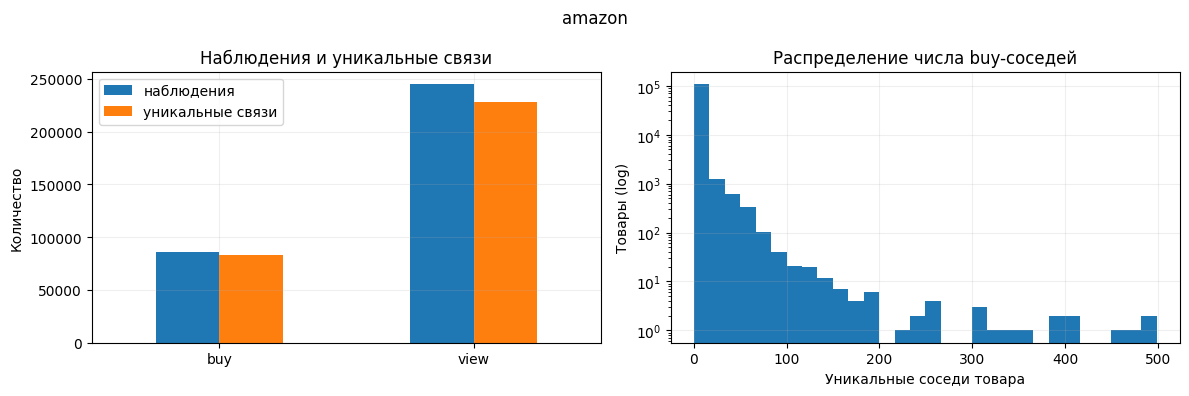

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Наблюдения и уникальные связи", ylabel="Количество")
if len(degree):
    degree.plot.hist(bins=30, ax=axes[1], logy=True)
axes[1].set(title="Распределение числа buy-соседей", xlabel="Уникальные соседи товара", ylabel="Товары (log)")
fig.suptitle(name)
plt.tight_layout()
plt.show()

## 2. Retailrocket

In [23]:
name = "retailrocket"
frame = read_table(DATA / name / "events.csv.gz")
pairs = read_table(DATA / name / "pairs.csv.gz")

### Примеры строк · events

In [24]:
print(f"{name}/events: {len(frame):,} строк × {len(frame.columns)} столбцов")
display(frame.sample(min(5, len(frame)), random_state=42))

retailrocket/events: 2,755,641 строк × 8 столбцов


,timestamp,user_id,event,item_id,transactionid,session_id,category_time,category
909614,2015-06-16 20:25:00.582000+00:00,852577,view,174719,<NA>,1066783,2015-05-10 03:00:00+00:00,1073
1483148,2015-07-13 23:42:04.869000+00:00,1301173,addtocart,351130,<NA>,1627731,2015-05-10 03:00:00+00:00,1421
722936,2015-06-07 02:21:08.171000+00:00,857117,view,391427,<NA>,1072684,2015-05-24 03:00:00+00:00,1385
917471,2015-06-17 01:24:52.125000+00:00,1130530,view,427541,<NA>,1414811,2015-05-10 03:00:00+00:00,343
2341314,2015-08-25 21:47:09.165000+00:00,900048,view,378914,<NA>,1126914,<NA>,<NA>


### Пропуски и дубликаты · events

In [25]:
quality(frame)

,пропуски,"пропуски, %"
timestamp,0,0.000000
user_id,0,0.000000
event,0,0.000000
item_id,0,0.000000
transactionid,2733184,99.185053
session_id,0,0.000000
category_time,656867,23.837176
category,656867,23.837176


Полных дубликатов: 0


### Примеры строк · pairs

In [26]:
print(f"{name}/pairs: {len(pairs):,} строк × {len(pairs.columns)} столбцов")
display(pairs.sample(min(5, len(pairs)), random_state=42))

retailrocket/pairs: 1,324,998 строк × 9 столбцов


,user_id,group_id,group_start,group_end,source_id,target_id,relation,source_category,target_category
218373,409424,512803,2015-06-10 20:00:16.878000+00:00,2015-06-10 20:31:00.892000+00:00,317435,448601,view,1558,1558
420729,710662,888981,2015-06-30 22:45:54.410000+00:00,2015-06-30 23:14:51.843000+00:00,191306,193745,view,1135,1135
202444,1143383,1430958,2015-06-09 15:07:35.251000+00:00,2015-06-09 18:54:56.528000+00:00,243566,418795,view,575,716
660680,1029286,1288092,2015-07-18 00:33:17.313000+00:00,2015-07-18 01:34:16.501000+00:00,228271,244310,view,196,120
617048,974226,1219019,2015-07-14 15:46:16.505000+00:00,2015-07-14 18:20:19.937000+00:00,64700,134906,view,1221,126


### Пропуски и дубликаты · pairs

In [27]:
quality(pairs)

,пропуски,"пропуски, %"
user_id,0,0.0
group_id,0,0.0
group_start,0,0.0
group_end,0,0.0
source_id,0,0.0
target_id,0,0.0
relation,0,0.0
source_category,0,0.0
target_category,0,0.0


Полных дубликатов: 0


### Количество наблюдений и уникальных пар

In [28]:
counts, degree = graph_stats(pairs, frame.item_id)
display(counts)

,наблюдения,уникальные связи
buy,7758,7052
view,1317240,1034911


### Плотность покупок

In [29]:
n_items = len(degree)
possible = n_items * (n_items - 1) // 2
density = 100 * counts.loc["buy", "уникальные связи"] / possible if possible else float("nan")
summary_rows[name] = {"товары": n_items,
                      "наблюдения buy": counts.loc["buy", "наблюдения"],
                      "наблюдения view": counts.loc["view", "наблюдения"], "уникальные buy": counts.loc["buy", "уникальные связи"],
                      "уникальные view": counts.loc["view", "уникальные связи"], "плотность buy, %": density}
print(f"Плотность покупок: {density:.5f}%")

Плотность покупок: 0.00003%


### Распределение связей

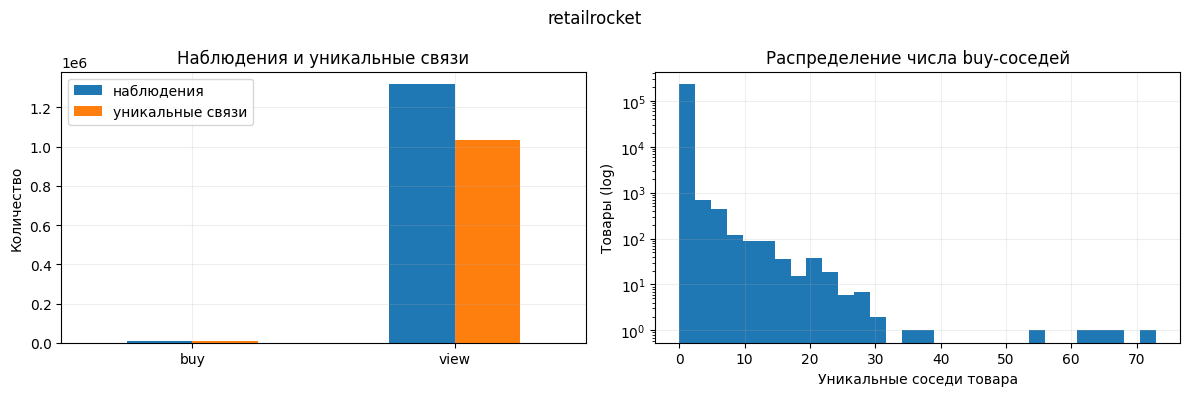

In [30]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Наблюдения и уникальные связи", ylabel="Количество")
if len(degree):
    degree.plot.hist(bins=30, ax=axes[1], logy=True)
axes[1].set(title="Распределение числа buy-соседей", xlabel="Уникальные соседи товара", ylabel="Товары (log)")
fig.suptitle(name)
plt.tight_layout()
plt.show()

## 3. REES46 Cosmetics Events

In [31]:
name = "rees46_cosmetics"
frame = read_table(DATA / name / "events.csv.gz")
pairs = read_table(DATA / name / "pairs.csv.gz")

### Примеры строк · events

In [32]:
print(f"{name}/events: {len(frame):,} строк × {len(frame.columns)} столбцов")
display(frame.sample(min(5, len(frame)), random_state=42))

rees46_cosmetics/events: 19,583,742 строк × 9 столбцов


,timestamp,event,item_id,category,category_code,brand,price,user_id,session_id
6016452,2019-11-17 17:21:39+00:00,view,5826657,1487580006350586771,appliances.environment.vacuum,NaN,29.71,529049405,52463b1e-de8b-491c-9464-8e0867c29ccb
14196548,2020-01-21 14:05:34+00:00,cart,5790563,1487580008263189483,<NA>,NaN,7.14,518920374,63e7264f-41d1-42b1-a3a7-9a62b01cd1dd
1349987,2019-10-10 14:56:16+00:00,cart,5684581,1487580013841613016,<NA>,estel,5.79,546365792,a177db03-6cc3-4559-94fd-e78b165939ba
19241357,2020-02-27 11:29:46+00:00,cart,5587780,1487580006317032337,<NA>,irisk,0.63,447393145,b71d6d21-6d8c-4d2b-a6cb-5e6149f44682
17858817,2020-02-16 18:43:02+00:00,view,5838078,1487580009143992338,<NA>,levrana,7.78,606845360,abe61d83-d707-46a1-bceb-5abbc3bb20cc


### Пропуски и дубликаты · events

In [33]:
quality(frame)

,пропуски,"пропуски, %"
timestamp,0,0.000000
event,0,0.000000
item_id,0,0.000000
category,0,0.000000
category_code,19240810,98.248894
brand,8265149,42.204135
price,0,0.000000
user_id,0,0.000000
session_id,4085,0.020859


Полных дубликатов: 0


### Примеры строк · pairs

In [34]:
print(f"{name}/pairs: {len(pairs):,} строк × {len(pairs.columns)} столбцов")
display(pairs.sample(min(5, len(pairs)), random_state=42))

rees46_cosmetics/pairs: 35,360,105 строк × 9 столбцов


,user_id,group_id,group_start,group_end,source_id,target_id,relation,source_category,target_category
16259357,550469726,3bf23d94-7453-42f9-8f83-e32ac9c2e22e,2019-10-31 17:48:02+00:00,2019-10-31 18:02:10+00:00,5674913,5674916,view,1487580007852147670,1487580007852147670
27589344,484961283,b4d58ab5-5f38-4a7b-bfd9-1e5d4249420b,2020-01-13 20:56:45+00:00,2020-01-13 20:58:01+00:00,5885319,5885321,view,2195085255176618020,1487580011308253293
35182456,218670245,97bc17ce-b7fa-487e-8291-bc6495b73310,2020-02-28 18:18:00+00:00,2020-02-28 18:36:37+00:00,33959,5663275,view,1487580005411062629,1487580005411062629
7824782,572112102,cafdddb9-9710-4de2-ad91-9e959eee19af,2020-01-15 12:49:36+00:00,2020-01-15 12:49:36+00:00,5622677,5857356,buy,1487580007281722301,1487580005134238553
2033805,564446839,2fbbe312-076d-44b5-90f4-eb8f233477f0,2019-10-26 17:32:30+00:00,2019-10-26 17:32:30+00:00,5013,5875987,buy,1487580008145748965,1487580008145748965


### Пропуски и дубликаты · pairs

In [35]:
quality(pairs)

,пропуски,"пропуски, %"
user_id,0,0.0
group_id,0,0.0
group_start,0,0.0
group_end,0,0.0
source_id,0,0.0
target_id,0,0.0
relation,0,0.0
source_category,0,0.0
target_category,0,0.0


Полных дубликатов: 0


### Количество наблюдений и уникальных пар

In [36]:
counts, degree = graph_stats(pairs, frame.item_id)
display(counts)

,наблюдения,уникальные связи
buy,11521008,7779980
view,23839097,13113113


### Плотность покупок

In [37]:
n_items = len(degree)
possible = n_items * (n_items - 1) // 2
density = 100 * counts.loc["buy", "уникальные связи"] / possible if possible else float("nan")
summary_rows[name] = {"товары": n_items,
                      "наблюдения buy": counts.loc["buy", "наблюдения"],
                      "наблюдения view": counts.loc["view", "наблюдения"], "уникальные buy": counts.loc["buy", "уникальные связи"],
                      "уникальные view": counts.loc["view", "уникальные связи"], "плотность buy, %": density}
print(f"Плотность покупок: {density:.5f}%")

Плотность покупок: 0.52251%


### Распределение связей

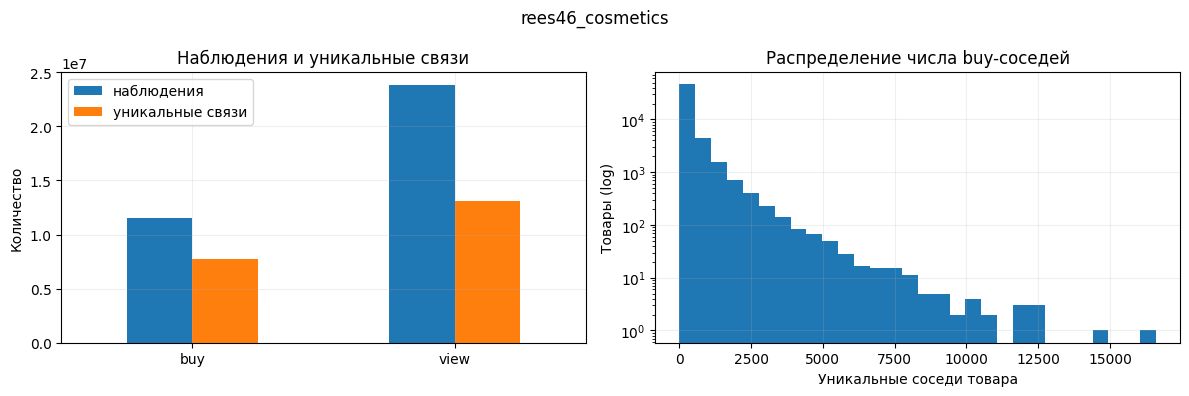

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Наблюдения и уникальные связи", ylabel="Количество")
if len(degree):
    degree.plot.hist(bins=30, ax=axes[1], logy=True)
axes[1].set(title="Распределение числа buy-соседей", xlabel="Уникальные соседи товара", ylabel="Товары (log)")
fig.suptitle(name)
plt.tight_layout()
plt.show()

## 4. REES46 Electronics Events

In [39]:
name = "rees46_electronics"
frame = read_table(DATA / name / "events.csv.gz")
pairs = read_table(DATA / name / "pairs.csv.gz")

### Примеры строк · events

In [40]:
print(f"{name}/events: {len(frame):,} строк × {len(frame.columns)} столбцов")
display(frame.sample(min(5, len(frame)), random_state=42))

rees46_electronics/events: 884,474 строк × 9 столбцов


,timestamp,event,item_id,category,category_code,brand,price,user_id,session_id
814917,2021-02-16 13:43:02+00:00,view,955354,2144415922528452715,electronics.telephone,NaN,30.95,1515915625606168132,5VuvY0VNcb
392912,2020-12-04 06:35:01+00:00,view,775032,2144415942703055498,<NA>,NaN,134.44,1515915625548338424,9nRnuby3Vy
302581,2020-11-17 20:57:49+00:00,view,1643174,2144415929902039340,appliances.personal.massager,centek,31.94,1515915625540579476,5YtzkJjFTi
531728,2021-01-01 13:50:54+00:00,view,255917,2144415921815421016,<NA>,NaN,10.32,1515915625571581042,RK6g3tO7bc
571507,2021-01-09 04:39:11+00:00,view,3642323,2144415921169498184,<NA>,xiaomi,16.51,1515915625574113371,7VnT9KBGx4


### Пропуски и дубликаты · events

In [41]:
quality(frame)

,пропуски,"пропуски, %"
timestamp,0,0.000000
event,0,0.000000
item_id,0,0.000000
category,0,0.000000
category_code,236047,26.687839
brand,212232,23.995279
price,0,0.000000
user_id,0,0.000000
session_id,162,0.018316


Полных дубликатов: 0


### Примеры строк · pairs

In [42]:
print(f"{name}/pairs: {len(pairs):,} строк × {len(pairs.columns)} столбцов")
display(pairs.sample(min(5, len(pairs)), random_state=42))

rees46_electronics/pairs: 437,444 строк × 9 столбцов


,user_id,group_id,group_start,group_end,source_id,target_id,relation,source_category,target_category
399702,1515915625599852988,hMon3Rc4fR,2021-02-15 18:54:58+00:00,2021-02-15 19:30:42+00:00,1571204,3606492,view,2144415924491387038,2144415924491387038
177287,1515915625549216460,VzorcIiNzZ,2020-12-05 19:26:22+00:00,2020-12-05 20:50:47+00:00,461183,1716641,view,2144415926890528986,2144415926848585945
111399,1515915625537675043,dIhn49gt9k,2020-11-10 08:08:50+00:00,2020-11-10 08:09:16+00:00,1768582,1803376,view,2144415926966026460,2144415926966026460
353573,1515915625600344832,6Et4va9iAc,2021-02-03 22:47:33+00:00,2021-02-03 23:33:09+00:00,877077,4079565,view,2144415922427789416,2144415922427789416
99911,1515915625536484287,uxOwy5lF0a,2020-11-06 21:39:33+00:00,2020-11-10 08:13:54+00:00,880512,3581989,view,2144415926848585945,2144415926848585945


### Пропуски и дубликаты · pairs

In [43]:
quality(pairs)

,пропуски,"пропуски, %"
user_id,0,0.0
group_id,0,0.0
group_start,0,0.0
group_end,0,0.0
source_id,0,0.0
target_id,0,0.0
relation,0,0.0
source_category,0,0.0
target_category,0,0.0


Полных дубликатов: 0


### Количество наблюдений и уникальных пар

In [44]:
counts, degree = graph_stats(pairs, frame.item_id)
display(counts)

,наблюдения,уникальные связи
buy,5517,4053
view,431927,260116


### Плотность покупок

In [45]:
n_items = len(degree)
possible = n_items * (n_items - 1) // 2
density = 100 * counts.loc["buy", "уникальные связи"] / possible if possible else float("nan")
summary_rows[name] = {"товары": n_items,
                      "наблюдения buy": counts.loc["buy", "наблюдения"],
                      "наблюдения view": counts.loc["view", "наблюдения"], "уникальные buy": counts.loc["buy", "уникальные связи"],
                      "уникальные view": counts.loc["view", "уникальные связи"], "плотность buy, %": density}
print(f"Плотность покупок: {density:.5f}%")

Плотность покупок: 0.00028%


### Распределение связей

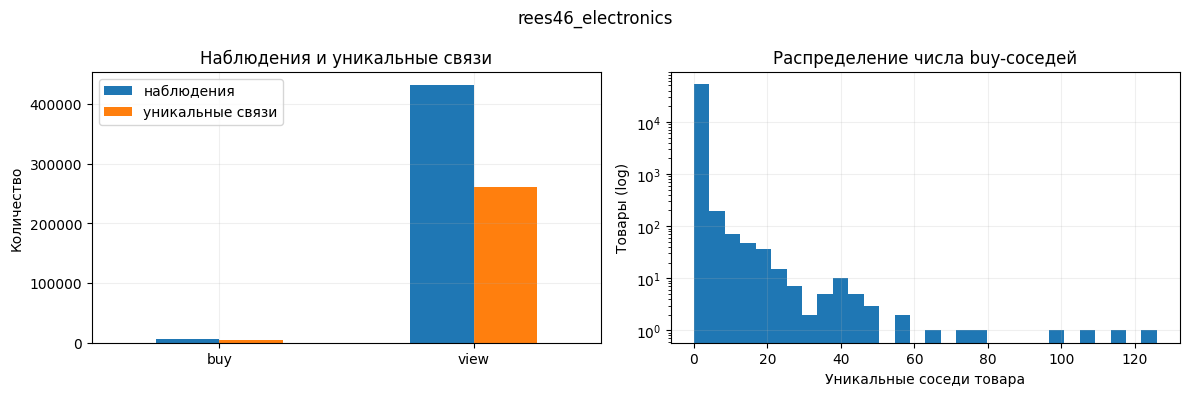

In [46]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
counts.plot.bar(ax=axes[0], rot=0)
axes[0].set(title="Наблюдения и уникальные связи", ylabel="Количество")
if len(degree):
    degree.plot.hist(bins=30, ax=axes[1], logy=True)
axes[1].set(title="Распределение числа buy-соседей", xlabel="Уникальные соседи товара", ylabel="Товары (log)")
fig.suptitle(name)
plt.tight_layout()
plt.show()

## 5. Сводка по датасетам

### Размеры каталогов и число связей

Наблюдение в Amazon — направленная ссылка метаданных, в журналах — пара товаров внутри группы пользователя. Уникальные связи считаются без направления: A–B и B–A образуют одну связь. Плотность покупок — доля уникальных buy-пар среди всех возможных неупорядоченных пар разных товаров полного подготовленного каталога, включая товары без покупочных связей.

In [ ]:
dataset_names = {
    "amazon": "Amazon Musical Instruments",
    "retailrocket": "Retailrocket",
    "rees46_cosmetics": "REES46 Cosmetics",
    "rees46_electronics": "REES46 Electronics",
}
columns = ["товары", "наблюдения buy", "наблюдения view",
           "уникальные buy", "уникальные view", "плотность buy, %"]
missing = [name for name in dataset_names
           if name not in summary_rows or not set(columns).issubset(summary_rows[name])]
if missing:
    raise ValueError("Повторно выполните разделы анализа: " + ", ".join(missing))

summary = pd.DataFrame.from_dict(summary_rows, orient="index").loc[list(dataset_names), columns]
summary.index.name = "Набор"
summary_display = summary.rename(index=dataset_names)
display(summary_display.style.format({
    **{column: "{:,.0f}" for column in columns if column != "плотность buy, %"},
    "плотность buy, %": "{:.6f}",
}, thousands=" ", decimal=","))

,товары,наблюдения buy,наблюдения view,уникальные buy,уникальные view,"плотность buy, %"
Набор,,,,,,
Amazon Musical Instruments,112 135,85 710,244 651,82 893,227 621,"0,001318"
Retailrocket,235 061,7 758,1 317 240,7 052,1 034 911,"0,000026"
REES46 Cosmetics,54 571,11 521 008,23 839 097,7 779 980,13 113 113,"0,522508"
REES46 Electronics,53 453,5 517,431 927,4 053,260 116,"0,000284"


### Соотношение просмотров и покупок

Отношения показывают, во сколько раз просмотров больше покупок. Отдельно сравниваются наблюдения и уникальные связи: повторные покупки одной пары могут увеличивать первое число, не меняя второе. Большой объём просмотров мотивирует проверку переноса, но сам по себе не доказывает его пользу.

In [ ]:
ratios = pd.DataFrame({
    "View / buy: наблюдения": summary["наблюдения view"] / summary["наблюдения buy"].replace(0, float("nan")),
    "View / buy: уникальные связи": summary["уникальные view"] / summary["уникальные buy"].replace(0, float("nan")),
}).rename(index=dataset_names)
display(ratios.style.format("{:.2f}", decimal=",", na_rep="Нет buy-связей"))

,View / buy: наблюдения,View / buy: уникальные связи
Набор,,
Amazon Musical Instruments,"2,85","2,75"
Retailrocket,"169,79","146,75"
REES46 Cosmetics,"2,07","1,69"
REES46 Electronics,"78,29","64,18"


### Число уникальных связей и плотность покупок

Обе вертикальные шкалы логарифмические: размеры графов и плотность различаются на несколько порядков. Плотность рассчитана по всему подготовленному каталогу, а не только по допустимым парам категорий. Нулевые значения на логарифмической шкале не отображаются.

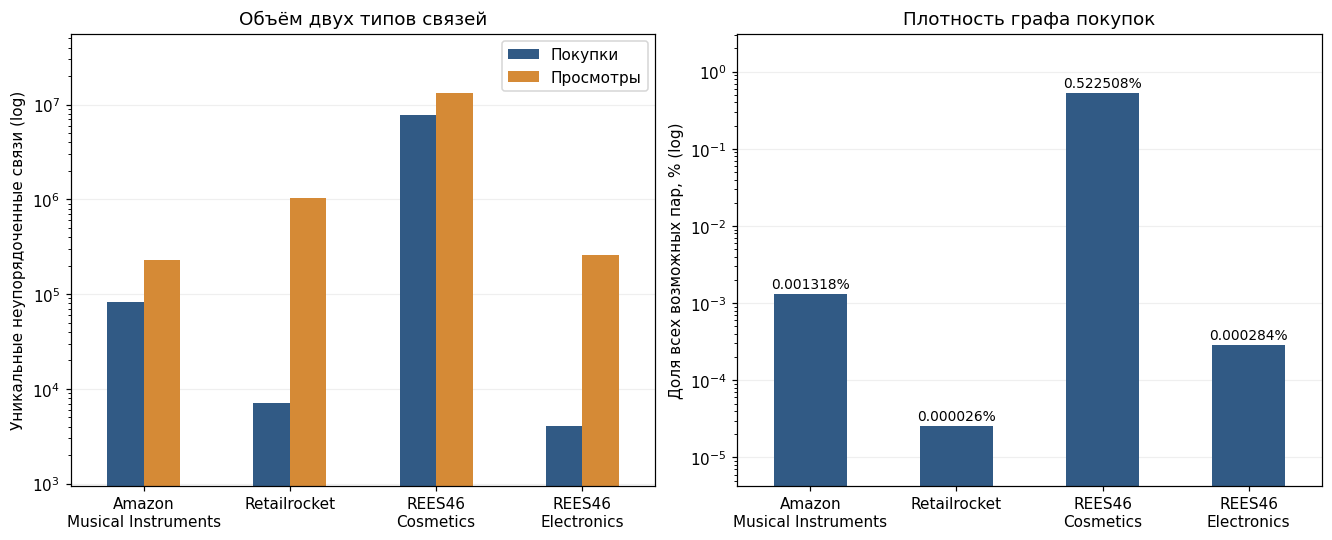

In [ ]:
labels = ["Amazon\nMusical Instruments", "Retailrocket", "REES46\nCosmetics", "REES46\nElectronics"]
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8), layout="constrained")

edges = summary[["уникальные buy", "уникальные view"]].rename(
    columns={"уникальные buy": "Покупки", "уникальные view": "Просмотры"})
edges = edges.where(edges.gt(0))
edges.plot.bar(ax=axes[0], color=["#315a85", "#d58a36"], rot=0)
axes[0].set(title="Объём двух типов связей", ylabel="Уникальные неупорядоченные связи (log)")

density = summary["плотность buy, %"]
density.where(density.gt(0)).plot.bar(ax=axes[1], color="#315a85", rot=0)
axes[1].set(title="Плотность графа покупок", ylabel="Доля всех возможных пар, % (log)")
for position, value in enumerate(density):
    if pd.notna(value) and value > 0:
        axes[1].text(position, value * 1.2, f"{value:.6f}%", ha="center", fontsize=9)

for ax in axes:
    ax.set_yscale("log")
    ax.set_xlabel("")
    ax.set_xticks(range(len(labels)), labels)
    ax.grid(axis="x", visible=False)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.margins(y=0.18)
plt.show()